# Calculus — Derivatives, Integrals, Taylor Series

Calculus studies how functions **change** (differential calculus) and how to **accumulate** quantities (integral calculus).


## The Derivative

The derivative of $f$ at $x$ is the **limit of the difference quotient**:

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$

Geometrically, $f'(x)$ is the **slope of the tangent line** at $(x, f(x))$.

For finite $h \neq 0$ the quotient gives the slope of a **secant line** through $(x, f(x))$ and $(x+h, f(x+h))$; as $h \to 0$ the secant converges to the tangent.

Example: $f(x) = \sin x \;\Rightarrow\; f'(x) = \cos x$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def f(x): return np.sin(x)
def f_prime(x): return np.cos(x)

def plot_derivative(x0, h):
    xv = np.linspace(0, 2 * np.pi, 500)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(xv, f(xv), 'b', lw=2, label='f(x) = sin x')

    if abs(h) < 1e-6:
        slope = f_prime(x0)
        label_slope = f"tangent: f'({x0:.2f}) = {slope:.3f}"
    else:
        slope = (f(x0 + h) - f(x0)) / h
        ax.plot(x0 + h, f(x0 + h), 'co', ms=6, label=f'f(x+h), h={h:.2f}')
        label_slope = f'secant slope = {slope:.3f}'

    tangent_y = f(x0) + slope * (xv - x0)
    ax.plot(xv, tangent_y, 'g--', lw=1.5, label=label_slope)
    ax.plot(x0, f(x0), 'ro', ms=7, label=f'f({x0:.2f}) = {f(x0):.3f}')
    ax.set(xlim=(0, 2 * np.pi), ylim=(-2, 2), xlabel='x', ylabel='f(x)')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title('Derivative as limit of the secant slope')
    plt.tight_layout(); plt.show()

wx = widgets.FloatSlider(value=1.0, min=0, max=2*np.pi, step=0.05, description='x₀')
wh = widgets.FloatSlider(value=1.0, min=-1.5, max=1.5, step=0.01, description='h')
display(widgets.VBox([wx, wh]),
        widgets.interactive_output(plot_derivative, {'x0': wx, 'h': wh}))


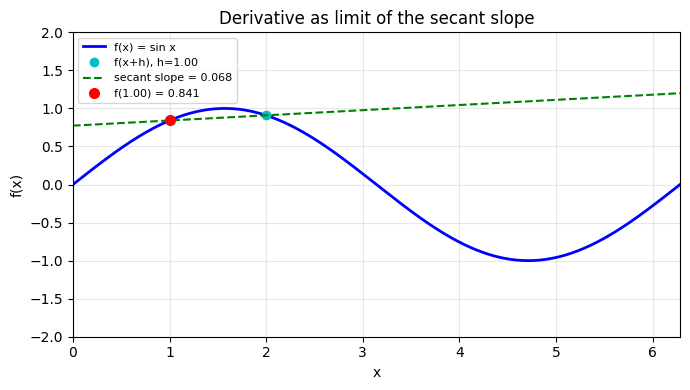

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_derivative(x0=wx.value, h=wh.value)

## The Definite Integral — Riemann Sums

The definite integral

$$\int_a^b f(x)\,dx = \lim_{n\to\infty} \sum_{k=0}^{n-1} f(x_k)\,\Delta x, \qquad \Delta x = \frac{b-a}{n}$$

measures the **signed area** between $f$ and the $x$-axis on $[a, b]$.

With finite $n$ rectangles we get a **Riemann sum** — an approximation that improves as $n$ grows.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display
import matplotlib.patches as patches

def f_int(x): return -(x - 5)**2 + 20

def plot_integral(n):
    a, b = 0, 10
    xv = np.linspace(a, b, 500)
    dx = (b - a) / n
    x_left = np.linspace(a, b - dx, n)
    riemann = np.sum(f_int(x_left) * dx)
    exact = np.trapezoid(f_int(xv), xv)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(xv, f_int(xv), 'b', lw=2, label='f(x) = −(x−5)² + 20')
    for xi in x_left:
        rect = patches.Rectangle((xi, 0), dx, f_int(xi), lw=0.8,
                                  edgecolor='steelblue', facecolor='lightblue', alpha=0.6)
        ax.add_patch(rect)
    ax.set(xlim=(0, 10), ylim=(0, 25), xlabel='x', ylabel='f(x)')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_title(f'n = {n} rectangles  |  Riemann ≈ {riemann:.2f}  |  Numerical ≈ {exact:.2f}')
    plt.tight_layout(); plt.show()

wn = widgets.IntSlider(value=5, min=1, max=100, step=1, description='n (rects)')
display(wn, widgets.interactive_output(plot_integral, {'n': wn}))


## Taylor Series

A Taylor series approximates a smooth function around a point $a$ using polynomials:

$$f(x) \approx \sum_{k=0}^{N} \frac{f^{(k)}(a)}{k!}\,(x - a)^k$$

For $\sin x$ expanded about $a = 0$ (Maclaurin series):

$$\sin x = x - \frac{x^3}{3!} + \frac{x^5}{5!} - \frac{x^7}{7!} + \cdots = \sum_{k=0}^{\infty} \frac{(-1)^k}{(2k+1)!}\,x^{2k+1}$$

Adding more terms improves the approximation over a wider interval.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display
from math import factorial

def taylor_sin(x, order):
    """Sum first `order` non-zero terms of the Maclaurin series for sin."""
    s = np.zeros_like(x)
    for k in range(order):
        s += ((-1)**k / factorial(2*k + 1)) * x**(2*k + 1)
    return s

def plot_taylor(order):
    x = np.linspace(-4 * np.pi, 4 * np.pi, 600)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(x, np.sin(x), 'k', lw=2, label='sin(x)')
    colors = plt.cm.viridis(np.linspace(0.2, 0.9, order))
    for n in range(1, order + 1):
        y = taylor_sin(x, n)
        deg = 2 * n - 1
        ax.plot(x, y, '--', color=colors[n-1], lw=1.2, label=f'order {n} (deg {deg})')
    ax.set(xlim=(-4*np.pi, 4*np.pi), ylim=(-3, 3), xlabel='x', ylabel='y')
    ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)
    ax.set_title(f'Taylor approximations of sin(x) — up to {order} terms')
    plt.tight_layout(); plt.show()

wo = widgets.IntSlider(value=1, min=1, max=8, step=1, description='# terms')
display(wo, widgets.interactive_output(plot_taylor, {'order': wo}))
